# SGD with Momentum on `customer_renewal_telemetry.csv`

In this notebook, we implement **SGD with Momentum** from scratch in NumPy and train a logistic regression model on `customer_renewal_telemetry.csv`.

Update rule at step $t$ (with momentum factor $\beta \in [0, 1)$, default $\beta = 0.9$):
$$v_t = \beta v_{t-1} + g_t$$
$$\theta_{t+1} = \theta_t - \eta v_t$$

We will track and compare:
1. Train vs. validation Binary Cross-Entropy (BCE) loss over epochs
2. Validation classification accuracy over epochs

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("/home/ipartzix/ML-Dataset/customer_renewal_telemetry.csv")
assert DATA_PATH.exists(), f"Dataset not found at {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

feature_cols = [
    "account_age_months",
    "monthly_usage_hours",
    "support_tickets_90d",
    "avg_session_minutes",
    "billing_failures_12m",
    "plan_tier_code",
]
target_col = "renewed_subscription"

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)

X_train_raw = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df[target_col].to_numpy(dtype=np.float64).reshape(-1, 1)

X_val_raw = val_df[feature_cols].to_numpy(dtype=np.float64)
y_val = val_df[target_col].to_numpy(dtype=np.float64).reshape(-1, 1)

# Standardize using train split only
mean = X_train_raw.mean(axis=0, keepdims=True)
std = X_train_raw.std(axis=0, keepdims=True) + 1e-8

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std

print("Loaded:", DATA_PATH)
print(f"Train: {X_train.shape}, Val: {X_val.shape}")

Loaded: /home/ipartzix/ML-Dataset/customer_renewal_telemetry.csv
Train: (2000, 6), Val: (500, 6)


In [2]:
class MomentumSGD:
    """SGD with momentum: v_t = beta * v_{t-1} + g_t; theta_{t+1} = theta_t - lr * v_t."""

    def __init__(self, lr: float = 0.05, beta: float = 0.9):
        if lr <= 0:
            raise ValueError("Learning rate lr must be positive.")
        if not (0.0 <= beta < 1.0):
            raise ValueError("Momentum beta must be in [0.0, 1.0).")
        self.lr = lr
        self.beta = beta
        self.v: np.ndarray | None = None

    def reset(self) -> None:
        self.v = None

    def step(self, params: np.ndarray, grads: np.ndarray) -> np.ndarray:
        if self.v is None:
            self.v = np.zeros_like(params, dtype=np.float64)

        self.v = self.beta * self.v + grads
        return params - self.lr * self.v


def sigmoid(z: np.ndarray) -> np.ndarray:
    z = np.clip(z, -40.0, 40.0)
    return 1.0 / (1.0 + np.exp(-z))


def bce_loss_and_grads(
    X: np.ndarray,
    y: np.ndarray,
    w: np.ndarray,
    b: np.ndarray,
    eps: float = 1e-12,
) -> tuple[float, np.ndarray, np.ndarray]:
    m = X.shape[0]
    probs = sigmoid(X @ w + b)
    probs_clipped = np.clip(probs, eps, 1.0 - eps)

    loss = -np.mean(y * np.log(probs_clipped) + (1.0 - y) * np.log(1.0 - probs_clipped))

    error = (probs - y) / m
    dw = X.T @ error
    db = np.sum(error, axis=0, keepdims=True)
    return float(loss), dw, db


def accuracy_score(
    X: np.ndarray,
    y: np.ndarray,
    w: np.ndarray,
    b: np.ndarray,
    threshold: float = 0.5,
) -> float:
    preds = (sigmoid(X @ w + b) >= threshold).astype(np.float64)
    return float(np.mean(preds == y))

In [3]:
rng = np.random.default_rng(42)
n_features = X_train.shape[1]

w = rng.normal(loc=0.0, scale=0.1, size=(n_features, 1))
b = np.zeros((1, 1), dtype=np.float64)

opt_w = MomentumSGD(lr=0.05, beta=0.9)
opt_b = MomentumSGD(lr=0.05, beta=0.9)

epochs = 50
batch_size = 64

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    perm = rng.permutation(X_train.shape[0])
    X_shuf = X_train[perm]
    y_shuf = y_train[perm]

    for start in range(0, X_train.shape[0], batch_size):
        end = start + batch_size
        xb = X_shuf[start:end]
        yb = y_shuf[start:end]

        _, dw, db = bce_loss_and_grads(xb, yb, w, b)
        w = opt_w.step(w, dw)
        b = opt_b.step(b, db)

    train_loss, _, _ = bce_loss_and_grads(X_train, y_train, w, b)
    val_loss, _, _ = bce_loss_and_grads(X_val, y_val, w, b)
    val_acc = accuracy_score(X_val, y_val, w, b)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

print(
    f"Epoch {epochs:02d} | "
    f"Train Loss: {train_losses[-1]:.4f} | "
    f"Val Loss: {val_losses[-1]:.4f} | "
    f"Val Accuracy: {val_accuracies[-1] * 100:.2f}%"
)

Epoch 50 | Train Loss: 0.5914 | Val Loss: 0.6021 | Val Accuracy: 67.00%


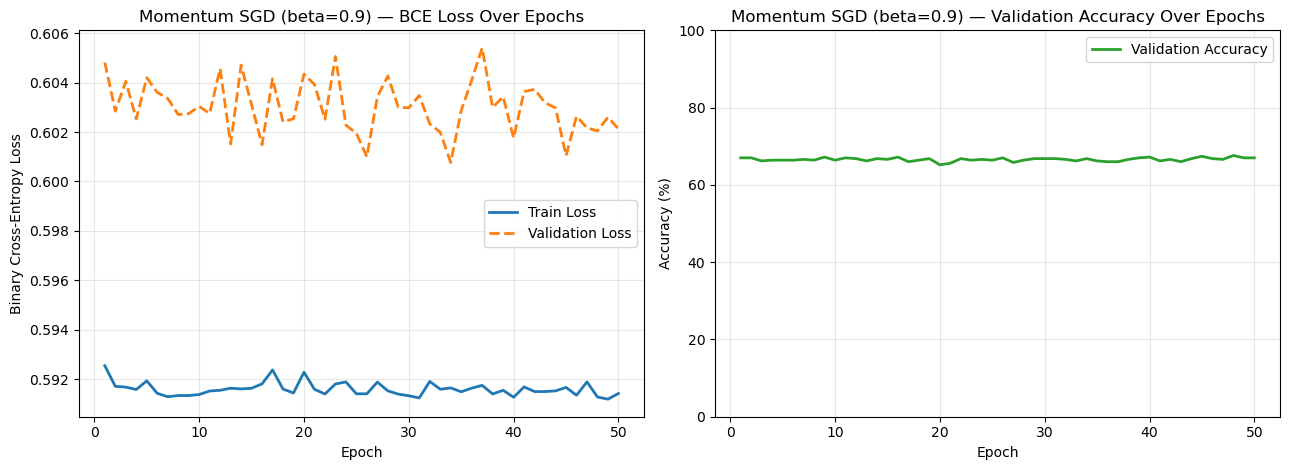

In [4]:
epochs_axis = np.arange(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Plot 1: Train vs. Validation Loss
axes[0].plot(epochs_axis, train_losses, label="Train Loss", linewidth=2)
axes[0].plot(epochs_axis, val_losses, label="Validation Loss", linewidth=2, linestyle="--")
axes[0].set_title("Momentum SGD (beta=0.9) — BCE Loss Over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Validation Accuracy
axes[1].plot(epochs_axis, np.array(val_accuracies) * 100.0, color="tab:green", label="Validation Accuracy", linewidth=2)
axes[1].set_title("Momentum SGD (beta=0.9) — Validation Accuracy Over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 100)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()